# Lab 1: Our Stock, Its Data, and Stationarity (JPM)

**Owner:** Member 1 · **Marking item covered:** 1. Data (10 marks), plus the look-ahead test used by item 2

This notebook answers the first part of the Baseline tier:

1. Which stock we forecast and why, and which predictors we use and why.
2. The date on which we downloaded the data.
3. The data quality report for our stock.
4. A candlestick chart for a period that we chose.
5. ADF and KPSS stationarity tests on the closing price and on the log return, with a conclusion.
6. The look-ahead test (`check_no_lookahead`) on the predictors that our group added.

Run it from top to bottom after **Kernel → Restart**. It needs no internet: it reads the snapshot in `data/`.

## Step 1: Set up

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
from statsmodels.tsa.stattools import adfuller, kpss

from tslab import config
from tslab.data import load_market_data, data_quality_report
from tslab.features import check_no_lookahead, log_return
from tslab.team import build_features_jpm, FEATURE_GROUPS_JPM

import warnings
warnings.filterwarnings("ignore")   # statsmodels warns when a KPSS p-value is outside its lookup table

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)
np.random.seed(config.SEED)

print("Target stock     :", config.TARGET_TICKER)
print("Predictors       :", config.PREDICTOR_TICKERS)
print("Snapshot         :", config.SNAPSHOT_START, "to", config.SNAPSHOT_END, "(end date exclusive)")
print("Walk-forward     : first training block", config.INITIAL_TRAIN, "days, test blocks of", config.TEST_SIZE, "days")

Target stock     : JPM
Predictors       : {'SP500': '^GSPC', 'TECH': 'XLK', 'VIX': '^VIX', 'US10Y': '^TNX', 'USD': 'DX-Y.NYB', 'BRENT': 'BZ=F', 'GOLD': 'GC=F', 'FIN': 'XLF'}
Snapshot         : 2015-01-01 to 2026-11-20 (end date exclusive)
Walk-forward     : first training block 1000 days, test blocks of 63 days


## Step 2: Our stock and our predictors

### Why JPMorgan Chase (JPM)?

* **It is not NVDA.** Using the notebooks' stock caps the grade at 60.
* **It matters to a portfolio manager.** JPM is the largest bank in the United States and one of the most widely held financial stocks, so a forecast of it is a realistic request from our client.
* **The data is long and clean.** Yahoo Finance has daily prices from 2015 onwards with no gaps (see the quality report below). That is about 11 years, far more than the roughly four years that the walk-forward settings need, so we keep `INITIAL_TRAIN = 1000`.
* **It is a different kind of company from the notebooks' example.** A bank earns money from the gap between the interest it receives and the interest it pays, so we expect interest rates and the banking sector to matter more for JPM than for a technology company. That gives us a question to test, instead of only repeating the notebooks.

### Which predictors, and why?

We keep the seven predictors that the lab provides, because each has a plausible link to a bank's share price:

| Predictor | Yahoo symbol | Why it could matter for JPM |
|:--|:--|:--|
| SP500 | ^GSPC | JPM is a large part of the US market and moves with it. |
| TECH | XLK | A broad risk-appetite signal. We expect it to matter **less** for a bank, and the ablation will test this. |
| VIX | ^VIX | Market fear. Banks fall hard in a panic (2020, March 2023). |
| US10Y | ^TNX | Interest rates drive a bank's lending margin. |
| USD | DX-Y.NYB | The dollar affects JPM's international business and global credit conditions. |
| BRENT | BZ=F | Oil moves inflation expectations, and therefore rates. |
| GOLD | GC=F | A safe-haven signal: money leaving risky assets. |

**We add one predictor: the Financial Select Sector fund (XLF), column `FIN`.** JPM is a bank, so the financial sector is its closest peer group, the same role that the technology fund plays for a technology stock. From it we build three features (in `tslab/team.py`): the sector's 1-day and 5-day returns, and whether JPM beat its own sector over the past week.

**Timing rule.** Every predictor uses only values known at the **close of day t**, and we forecast the return from t to t+1. So every predictor is known before the day that we forecast. Step 7 proves this with the look-ahead test.

### Download date

We downloaded the data from Yahoo Finance with `python download_data.py --target JPM` on **20 November 2026**. The snapshot covers **2 January 2015 to 19 November 2026**. Prices are adjusted for splits and dividends, and Yahoo rewrites adjusted history each time a dividend is paid, so a download on another day can give slightly different numbers.

## Step 3: Load the data

In [2]:
data = load_market_data()
print(f"Columns: {list(data.columns)}")
data.tail()

Loaded 2989 trading days of JPM, 2015-01-02 to 2026-11-19, with 8 predictor series.
Columns: ['Open', 'High', 'Low', 'Close', 'Volume', 'SP500', 'TECH', 'VIX', 'US10Y', 'USD', 'BRENT', 'GOLD', 'FIN']


,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD,FIN
Date,,,,,,,,,,,,,
2026-11-13,346.410004,346.799988,342.790009,346.190002,4198800,7561.669922,170.279999,19.299999,5.154,103.410004,95.839996,3886.300049,58.680000
2026-11-16,345.570007,346.519989,336.670013,338.209991,7250300,7416.589844,164.759995,22.910000,5.121,103.550003,92.440002,3853.000000,58.180000
2026-11-17,333.570007,336.890015,328.739990,329.959991,8210200,7340.529785,163.259995,25.459999,5.103,103.489998,93.139999,3864.199951,57.070000
2026-11-18,327.519989,330.089996,323.709991,324.109985,6778200,7323.629883,163.809998,24.559999,5.066,103.860001,91.949997,3741.899902,56.419998
2026-11-19,326.380005,328.269989,317.429993,320.220001,6968100,7175.830078,160.690002,28.440001,5.052,103.900002,91.980003,3685.500000,55.580002


## Step 4: Data quality report

The report counts the problems that most often break a forecasting project: duplicated dates, missing values, impossible prices, days with no trading, long gaps, and extreme moves.

In [3]:
quality = data_quality_report(data)
quality.to_frame("JPM")

,JPM
rows,2989
first_date,2015-01-02
last_date,2026-11-19
duplicate_dates,0
missing_values,0
non_positive_prices,0
days_with_zero_volume,0
high_below_low,0
longest_gap_in_days,4
days_with_move_over_10pct,7


In [4]:
# The extreme days deserve a closer look: are they data errors or real events?
daily_move = data["Close"].pct_change()
big_moves = daily_move[daily_move.abs() > 0.10]
pd.DataFrame({"Close": data.loc[big_moves.index, "Close"].round(2),
              "Daily change": (big_moves * 100).round(1).astype(str) + " %"})

,Close,Daily change
Date,,
2020-03-09,78.19,-13.5 %
2020-03-13,86.95,18.0 %
2020-03-16,73.94,-15.0 %
2020-03-18,70.20,-10.5 %
2020-03-24,74.00,11.9 %
2020-11-09,100.73,13.5 %
2024-11-06,237.37,11.5 %


In [5]:
# How many trading days per year? About 252 is normal for a US stock.
data.groupby(data.index.year).size().to_frame("trading days").T

Date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
trading days,252,252,251,251,252,253,252,251,250,252,250,223


## Step 5: Candlestick charts

We chose two periods.

1. **The 2023 US banking crisis (February to May 2023).** Silicon Valley Bank failed on 10 March 2023, and JPM bought First Republic Bank on 1 May 2023. This is the most important bank-specific event in our data, so it shows how JPM behaves when its own sector is under stress.
2. **The last 90 trading days**, the period just before the forecast that the client asked for.

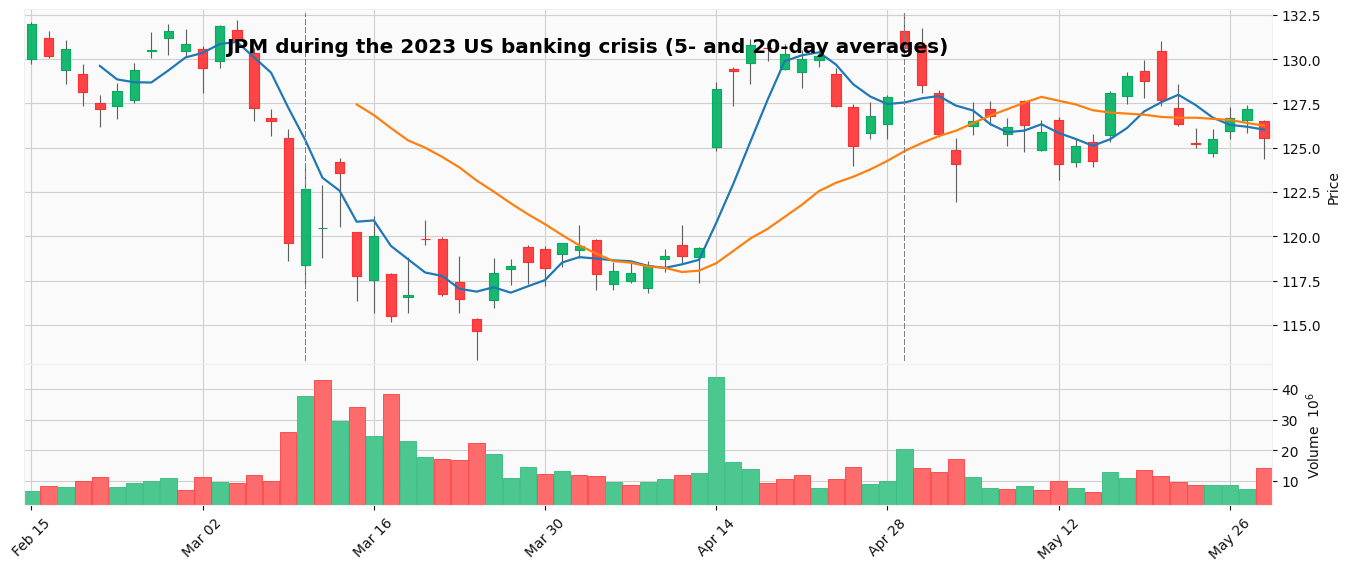

In [6]:
crisis = data.loc["2023-02-15":"2023-05-31", ["Open", "High", "Low", "Close", "Volume"]]
mpf.plot(crisis, type="candle", style="yahoo", volume=True, mav=(5, 20),
         figratio=(25, 10), tight_layout=True,
         title="JPM during the 2023 US banking crisis (5- and 20-day averages)",
         vlines=dict(vlines=["2023-03-10", "2023-05-01"], colors="grey", linestyle="--", linewidths=1))

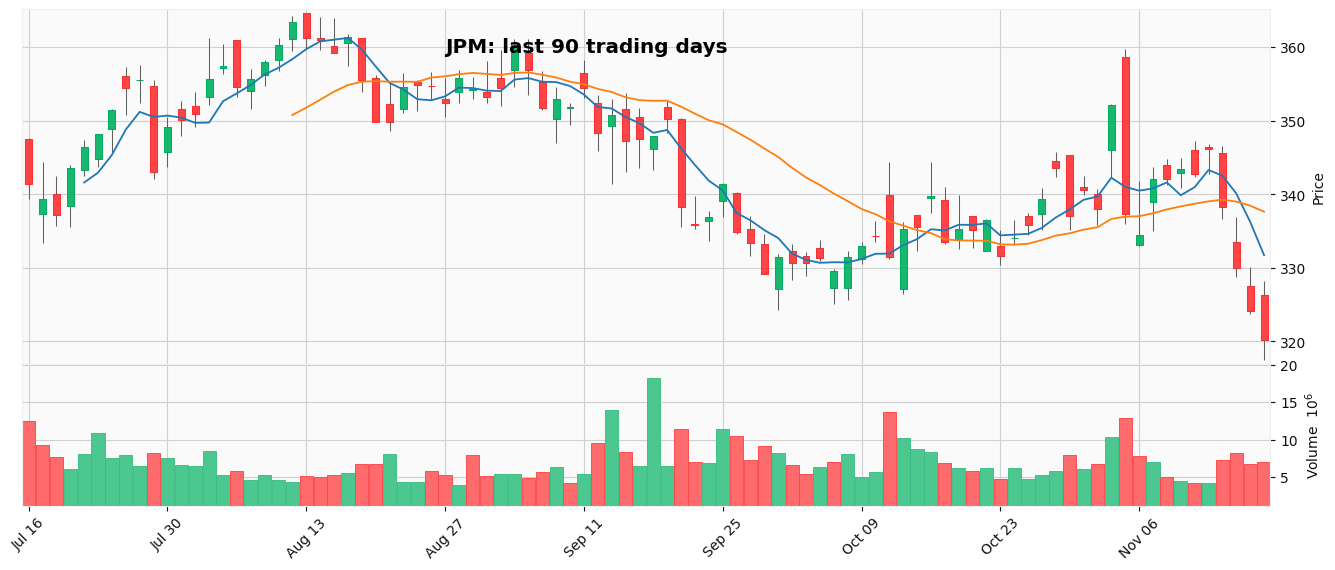

In [7]:
recent = data.tail(90)[["Open", "High", "Low", "Close", "Volume"]]
mpf.plot(recent, type="candle", style="yahoo", volume=True, mav=(5, 20),
         figratio=(25, 10), tight_layout=True, title="JPM: last 90 trading days")

## Step 6: Price, log return, and stationarity

We forecast the **log return** `ln(P_t / P_{t-1})`, not the price. First we look at both series with a 63-day (about one quarter) rolling mean and rolling standard deviation. Then we test them.

* **ADF test.** Null hypothesis: the series is **not** stationary (it has a unit root). A p-value below 0.05 rejects that, which is evidence **for** stationarity.
* **KPSS test.** Null hypothesis: the series **is** stationary. A p-value below 0.05 is evidence **against** stationarity.

The two tests ask opposite questions, so we only call a series stationary when both agree.

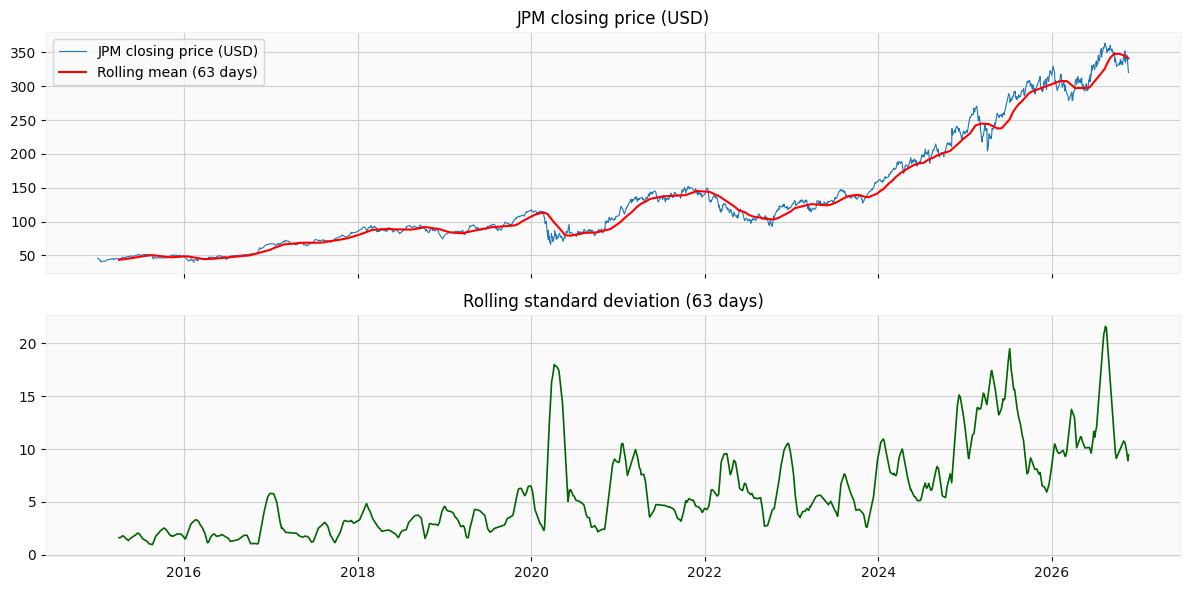

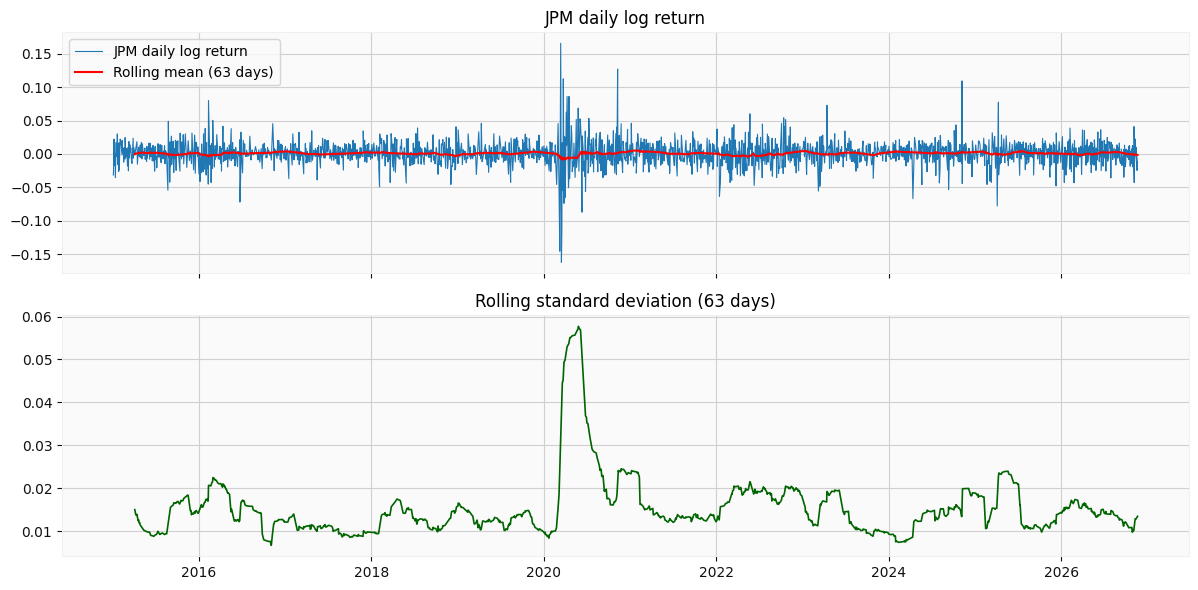

In [8]:
price = data["Close"]
logret = log_return(price).dropna()

def plot_with_rolling(series, title, window=63):
    fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    top.plot(series, linewidth=0.8, label=title)
    top.plot(series.rolling(window).mean(), color="red", linewidth=1.5, label=f"Rolling mean ({window} days)")
    top.legend(loc="upper left"); top.set_title(title)
    bottom.plot(series.rolling(window).std(), color="darkgreen", linewidth=1.2)
    bottom.set_title(f"Rolling standard deviation ({window} days)")
    plt.tight_layout(); plt.show()

plot_with_rolling(price, "JPM closing price (USD)")
plot_with_rolling(logret, "JPM daily log return")

In [9]:
def stationarity_report(series, name):
    """ADF and KPSS on one series, with a one-word verdict."""
    series = series.dropna()
    adf_stat, adf_p = adfuller(series, autolag="AIC")[:2]
    kpss_stat, kpss_p = kpss(series, regression="c", nlags="auto")[:2]
    adf_stationary = adf_p < 0.05
    kpss_stationary = kpss_p >= 0.05
    if adf_stationary and kpss_stationary:
        verdict = "Stationary (both tests agree)"
    elif not adf_stationary and not kpss_stationary:
        verdict = "Non-stationary (both tests agree)"
    else:
        verdict = "Tests disagree: look closer"
    return {"Series": name, "ADF statistic": adf_stat, "ADF p-value": adf_p,
            "KPSS statistic": kpss_stat, "KPSS p-value": kpss_p, "Verdict": verdict}

stationarity = pd.DataFrame([
    stationarity_report(price, "Closing price"),
    stationarity_report(logret, "Daily log return"),
]).set_index("Series")
stationarity.round(4)

,ADF statistic,ADF p-value,KPSS statistic,KPSS p-value,Verdict
Series,,,,,
Closing price,1.0449,0.9947,7.3019,0.01,Non-stationary (both tests agree)
Daily log return,-15.6054,0.0000,0.0417,0.10,Stationary (both tests agree)


In [10]:
# statsmodels caps the KPSS p-value at 0.01 (smallest) and 0.10 (largest) of its lookup table,
# so read 0.01 as "0.01 or smaller" and 0.10 as "0.10 or larger".
for name, row in stationarity.iterrows():
    print(f"{name}: ADF p = {row['ADF p-value']:.4f}, KPSS p = {row['KPSS p-value']:.4f} -> {row['Verdict']}")

Closing price: ADF p = 0.9947, KPSS p = 0.0100 -> Non-stationary (both tests agree)
Daily log return: ADF p = 0.0000, KPSS p = 0.1000 -> Stationary (both tests agree)


## Step 7: Look-ahead test on the predictors we added

The lab requires `check_no_lookahead` on every feature that we add. The test computes the features twice, once with all the data and once with everything after a chosen date deleted. If any feature value on that date changes, the feature was using the future. We test 20 random dates.

In [11]:
assert check_no_lookahead(data, build_features_jpm, n_checks=20, seed=config.SEED)
print("Passed: none of the", sum(len(g) for g in FEATURE_GROUPS_JPM.values()),
      "features (including the 3 new financial-sector features) uses information from after its own date.")

Passed: none of the 50 features (including the 3 new financial-sector features) uses information from after its own date.


## Step 8: Does the financial sector move with JPM more than the technology sector does?

A first, simple check of our predictor choice: the same-day correlation of daily log returns. This is **not** a forecast (same-day correlation does not mean that today's sector return predicts tomorrow's JPM return). It only shows which markets JPM moves with. Whether the predictors help a **forecast** is tested in Lab 3 with the feature ablation.

In [12]:
returns = np.log(data[["Close", "SP500", "TECH", "FIN", "GOLD", "BRENT", "USD", "VIX"]]).diff()
returns["US10Y (change)"] = data["US10Y"].diff()
corr = returns.corr()["Close"].drop("Close").sort_values(ascending=False)
corr.to_frame("Correlation with JPM's daily return").round(3)

,Correlation with JPM's daily return
FIN,0.912
SP500,0.714
TECH,0.533
US10Y (change),0.294
BRENT,0.213
USD,-0.021
GOLD,-0.055
VIX,-0.527


In [13]:
# And the question that matters for forecasting: does TODAY's value predict TOMORROW's JPM return?
next_day = np.log(data["Close"]).diff().shift(-1)
lagged = returns.drop(columns="Close").corrwith(next_day).sort_values()
lagged.to_frame("Correlation with JPM's NEXT-day return").round(3)

,Correlation with JPM's NEXT-day return
FIN,-0.091
SP500,-0.086
TECH,-0.059
USD,-0.014
US10Y (change),-0.012
BRENT,-0.004
VIX,-0.000
GOLD,0.004


## Step 9: What we found

*(Member 1 writes this in their own words after running the notebook. The draft below describes the results of our 20 November 2026 snapshot. Check every number against the output above before submitting.)*

**The data is clean enough to model.** We have 2,989 trading days with no missing values, no duplicated dates, no zero-volume days and no impossible prices. The longest gap is 4 calendar days, which is a holiday weekend. Each full year has 250 to 253 trading days, as expected for a US stock (2026 has 223 because the year is not over).

**The extreme days are real events, not errors.** Seven days moved more than 10%. Six are in 2020: the COVID crash in March 2020 (falls of 13.5% and 15.0%, a rebound of 18.0%), and 9 November 2020, when the first vaccine result was announced (+13.5%). The seventh is 6 November 2024 (+11.5%), the day after the US presidential election. We keep them because they really happened, but they will dominate the error in any test block that contains them, and a model trained on calm years will not expect them.

**The banking crisis chart shows how JPM reacts to stress in its own sector.** After Silicon Valley Bank failed (10 March 2023), JPM fell from about $131 to about $115 in two weeks, and volume roughly quadrupled. The price recovered sharply when JPM reported its quarterly results in mid-April. The purchase of First Republic (1 May) caused little movement. The sector, not the market, drove this episode, which supports adding the financial-sector predictor.

**The forecast starts in a nervous market.** On our last day (19 November 2026) JPM closed at $320.22, about 7.5% below its close of $346.19 on 13 November, and the VIX rose from 19.3 to 28.4 over the same days. A forecast that starts in a volatile period should have a wide range.

**Stationarity: we must model returns, not prices.** For the closing price, the ADF p-value is 0.995 (we cannot reject a unit root) and the KPSS p-value is 0.01 or smaller (we reject stationarity). Both tests agree that the price is **non-stationary**. For the daily log return, the ADF p-value is below 0.0001 and the KPSS p-value is 0.10 or larger. Both tests agree that the log return is **stationary**. This is why every model in our project forecasts the log return and converts it to a price afterwards. The rolling plots add one warning: the **mean** of the return is stable around zero, but its **spread** is not. The 63-day standard deviation is usually 1% to 2% a day but reached almost 6% in 2020 (volatility clustering). So a fixed-width forecast range would be too narrow in a crisis and too wide in calm periods.

**The predictors we added are honest.** All 50 features, including the three financial-sector features, passed the look-ahead test on 20 random dates.

**JPM moves with its sector far more than with technology.** The same-day correlation of JPM's return with the financial-sector fund is 0.91, against 0.53 for the technology fund and 0.71 for the S&P 500. But the correlation of **today's** market moves with **tomorrow's** JPM return is close to zero for every predictor (the largest is −0.09, for the financial sector, a slight tendency to reverse). This is our first sign that forecasting JPM's next-day return will be hard, and that any improvement over the naive forecast will be small. Labs 2 to 5 test exactly that.